# Twin Neural Network Training with PyTorch and fast.ai

In [2]:
from pathlib import Path
import os

import cv2 
from PIL import Image
import numpy as np
import math

from fastcore.all import *
from fastai.vision.all import *
from fastai.layers import AdaptiveConcatPool2d

import torch
import torchvision.models as models
import torch.nn as nn
from torchvision import transforms

MODELS_DIR = Path("./twin_models")
os.makedirs(MODELS_DIR, exist_ok=True   )

RESULTS_DIR = Path("./twin_results")
os.makedirs(RESULTS_DIR, exist_ok=True   )

DS_ROOT = Path('ASC_dataset_v3_augmented')


## Extract Patches

In [3]:
class Patch:
    "Holds the crop + meta about one patch."
    def __init__(self, page_path:Path, bbox:tuple[int,int,int,int], script:str):
        # bbox = (x, y, w, h) with w = h = patch_size
        self.page_path,self.bbox,self.script = Path(page_path),bbox,script
        self.page_id = "_".join(Path(page_path).stem.split("_")[:2])  # ms_id_page_id

    def pil(self):
        """
        Return a padded patch as a 3-channel PILImage of size (patch_size × patch_size).
        We DO NOT convert to grayscale. Padding is applied equally across all channels.
        """
        img = cv2.imread(str(self.page_path), cv2.IMREAD_COLOR)  # <- KEEP ORIGINAL COLOR
        if img is None:
            raise FileNotFoundError(f"Could not read image: {self.page_path}")

        H, W, C = img.shape

        x, y, w, h = self.bbox   # here w = h = patch_size

        # Allocate full patch (filled with zeros)
        patch = np.zeros((h, w, C), dtype=img.dtype)

        # Overlap region
        x_end = min(x + w, W)
        y_end = min(y + h, H)
        ov_w = max(0, x_end - x)
        ov_h = max(0, y_end - y)

        if ov_w > 0 and ov_h > 0:
            patch[0:ov_h, 0:ov_w] = img[y:y_end, x:x_end]

        # Convert BGR → RGB for fastai/PIL
        patch_rgb = cv2.cvtColor(patch, cv2.COLOR_BGR2RGB)

        return PILImage.create(patch_rgb)

    def __fspath__(self) -> str: return str(self.page_path)
    def __str__(self) -> str: return str(self.page_path)



def extract_patches(page_path: Path, *, patch_size: int = 224):
    """
    Extract patches of fixed size (patch_size × patch_size).
    At the edges, patches are padded inside Patch.pil(), NO GRAYSCALE conversion.
    """
    script = page_path.parent.name  # 'french' | 'german'

    img = cv2.imread(str(page_path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Could not read image: {page_path}")

    h, w, _ = img.shape

    patches = L()

    # Always crop bbox of size patch_size × patch_size
    for y in range(0, h, patch_size):
        for x in range(0, w, patch_size):
            bbox = (x, y, patch_size, patch_size)
            patches.append(Patch(page_path, bbox, script))

    return patches

In [12]:
page_files  = get_image_files(DS_ROOT / "train") + get_image_files(DS_ROOT / "val")

patches = L()
for p in page_files:
    patches += extract_patches(p, patch_size=224)

print(f"Found {len(patches):,} patches") 

Found 128,370 patches


## Comon Module Deffinitions

Encoding Network

In [13]:

encoder = nn.Sequential(
    *list(models.resnet50(pretrained=True).children())[:-2]
)



Fully Connected Network

In [14]:

head = nn.Sequential(
            AdaptiveConcatPool2d(1),
            nn.Flatten(),
            nn.BatchNorm1d(8192),
            nn.Dropout(0.05),
            nn.Linear(8192, 512, False),
            nn.ReLU(True),
            nn.BatchNorm1d(512),
            nn.Dropout(0.1),
            nn.Linear(512, 2, False)
        )

Pytorch Transforms

In [15]:

image_tfm = transforms.Compose(
            [
                transforms.ToTensor(),
                transforms.Normalize(
                    mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
                ),
            ]
        )

## Pre-train the Encoder using a Siamese Neural Net

Twin Network

In [16]:
class TwinModel(Module):
    def __init__(self, encoder, head):
        super().__init__()
        self.encoder, self.head = encoder, head

    def forward(self, x1, x2):
        ftrs = torch.cat([self.encoder(x1), self.encoder(x2)], dim=1)
        return self.head(ftrs)

model = TwinModel(encoder, head)

Twin Image Class

In [17]:
class TwinImage(fastuple):
    @staticmethod
    def img_restore(image: torch.Tensor):
        imin, imax = image.min(), image.max()
        if (imax - imin) > 0:
            return (image - imin) / (imax - imin)
        else:
            return image  # constant image; nothing to rescale

    def show(self, ctx=None, **kwargs):
        """
        Show the two images with a separator.
        Default title: Similar/Not similar + page ids.
        Can be overridden via `title=` in kwargs.
        """
        # ------------------- unpack meta -------------------
        if len(self) > 2:
            img1, img2, meta, *rest = self
            same, pid1, pid2 = meta

            if isinstance(same, Tensor):
                same_val = int(same.item())
            else:
                same_val = int(same)

            same_txt = "Similar" if same_val == 1 else "Not similar"
            default_title = f"{same_txt} | page1: {pid1} | page2: {pid2}"
        else:
            img1, img2 = self
            default_title = "Undetermined"

        # Allow external override
        title = kwargs.pop("title", default_title)

        # ------------------- tensor handling -------------------
        if not isinstance(img1, Tensor):
            t1, t2 = image_tfm(img1), image_tfm(img2)
        else:
            t1, t2 = img1, img2

        # Remove batch dim if present
        if t1.ndim == 4:
            t1, t2 = t1[0], t2[0]

        # If HWC, convert to CHW
        if t1.ndim == 3 and t1.shape[0] not in (1, 3):
            t1 = t1.permute(2, 0, 1)
            t2 = t2.permute(2, 0, 1)

        C, H, W1 = t1.shape
        _, _, W2 = t2.shape

        line = t1.new_zeros(C, H, 10)

        combo = torch.cat(
            [self.img_restore(t1), line, self.img_restore(t2)],
            dim=2
        )
        return show_image(combo, title=title, ctx=ctx, **kwargs)


Label Func

In [18]:
def label_func(patch):
    return (patch.script, patch.page_id)

TwinTransform Class

In [19]:

class ComponentTwinTransform(Transform):
    "Generate (img1,img2,same?) from Patch objects."
    def __init__(self, patches:L, label_func, splits):
        # unpack script labels only for similarity pairing
        self.labels     = patches.map(lambda p: label_func(p)[0]).unique()  # ['french','german']
        self.lbl2items  = {l: L(p for p in patches if label_func(p)[0]==l) for l in self.labels}
        self.label_func = label_func
        self.valid      = {p: self._draw(p) for p in patches[splits[1]]}

    def encodes(self, p):
        p2, same = self.valid.get(p, self._draw(p))
        img1, img2 = p.pil(), p2.pil()

        if (p not in self.valid) and random.random() < .5:
            img1, img2 = img2, img1

        img1, img2 = image_tfm(img1), image_tfm(img2)

        # Return also page ids → can be used in loss later
        script, pid1 = self.label_func(p)
        _,      pid2 = self.label_func(p2)
        return TwinImage(img1, img2, fastuple(torch.tensor(same, dtype=torch.long), pid1, pid2))

    def _draw(self, c):
        same = random.random() < .5
        script, _ = self.label_func(c)
        if not same:  # negative pair
            script = random.choice(L(l for l in self.labels if l != script))
        return random.choice(self.lbl2items[script]), same


Split and Dataloader

<Axes: title={'center': 'Not similar | page1: 043_003 | page2: 028_000'}>

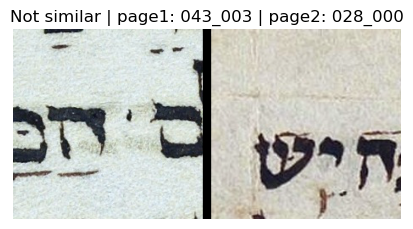

In [20]:
splits =  GrandparentSplitter (train_name='train', valid_name='val')(patches)
tfm = ComponentTwinTransform(patches, label_func, splits)
tfm(patches[0]).show()

<Axes: title={'center': 'Not similar | page1: 001_003 | page2: 006_001'}>

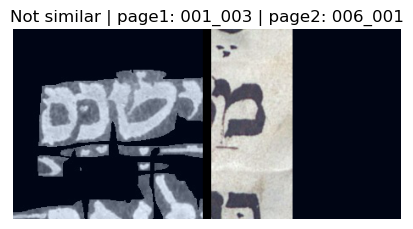

In [21]:
tls = TfmdLists(patches, tfm, splits=splits)
show_at(tls.valid, 0)

In [22]:
dls = tls.dataloaders(
    bs=32,
    # after_batch=[*aug_transforms()],
    after_batch=[Brightness(), Contrast()]
)

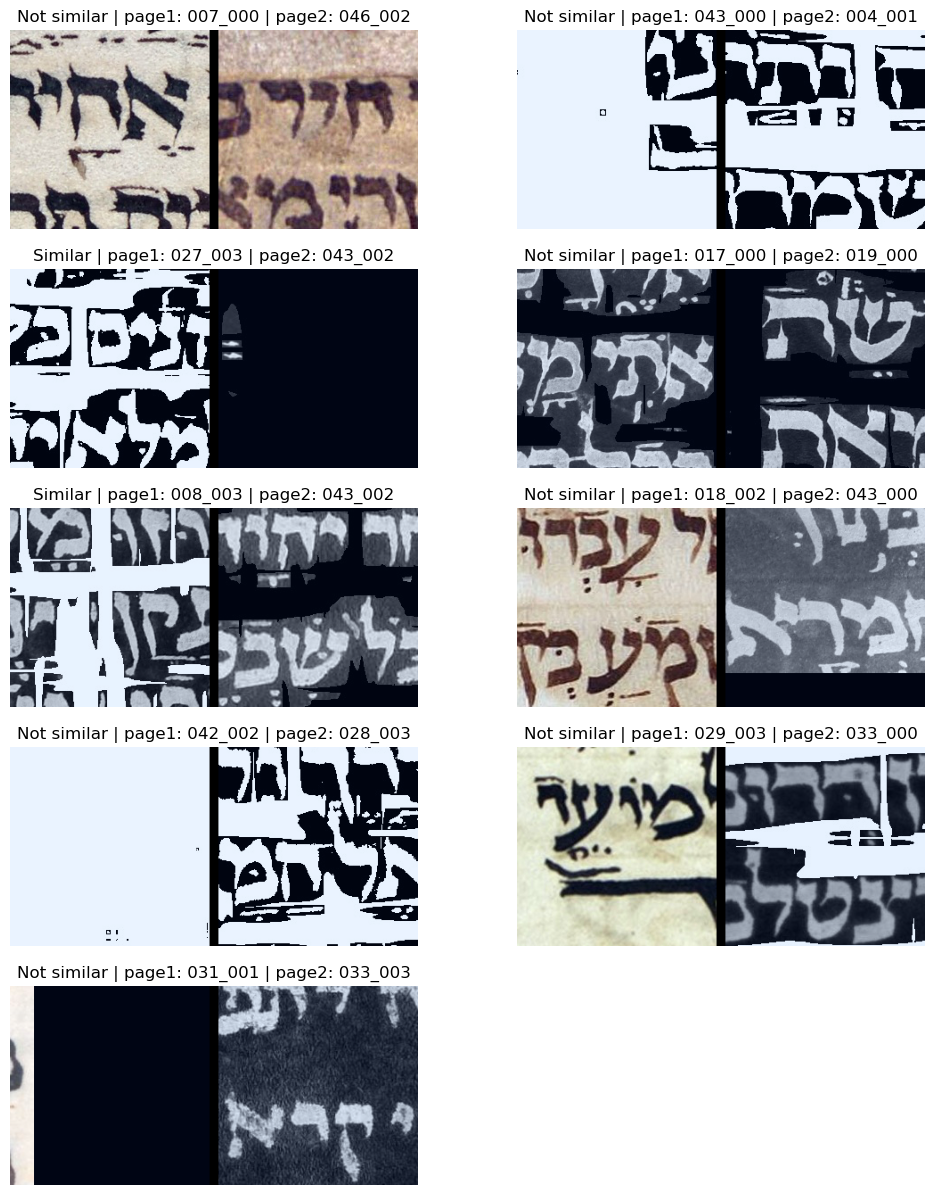

In [23]:

@typedispatch
def show_batch(
    x: TwinImage,
    y,
    samples,
    ctxs=None,
    max_n=6,
    nrows=None,
    ncols=2,
    figsize=None,
    **kwargs
):
    # x is a TwinImage of batched tensors:
    # x[0]: (bs, C, H, W)  first image
    # x[1]: (bs, C, H, W)  second image
    # x[2]: (same_batch, pid1_batch, pid2_batch)
    if figsize is None:
        figsize = (ncols * 6, math.ceil(max_n / ncols) * 3)

    bs = x[0].shape[0]
    n = min(bs, max_n)

    if ctxs is None:
        ctxs = get_grid(n, nrows=nrows, ncols=ncols, figsize=figsize)

    for i, ctx in enumerate(ctxs[:n]):
        img1_i = x[0][i]           # (C,H,W)
        img2_i = x[1][i]           # (C,H,W)
        same_i = x[2][0][i]        # tensor scalar 0/1
        pid1_i = x[2][1][i]        # page id 1 (string)
        pid2_i = x[2][2][i]        # page id 2 (string)

        TwinImage(img1_i, img2_i, fastuple(same_i, pid1_i, pid2_i)).show(
            ctx=ctx,
            **kwargs
        )

    return ctxs 

dls.show_batch()

Loss Function

In [24]:

class SiameseHierarchicalLoss(nn.Module):
    def __init__(self, alpha=1.0, beta=0.5):
        """
        alpha: weight for normal similarity loss
        beta : weight for page-consistency penalty
        """
        super().__init__()
        self.ce = nn.CrossEntropyLoss()
        self.alpha = alpha
        self.beta = beta

    def forward(self, out, targ):
        """
        out  : [N, 2] logits
        targ : tuple (same, pid1, pid2)
            - same : tensor [N] (0/1 or False/True)
            - pid1 : list of strings
            - pid2 : list of strings
        """
        same, pid1, pid2 = targ

        # 1. similarity classification loss
        same = same.long()  # CE expects ints
        sim_loss = self.ce(out, same)

        # 2. page-consistency penalty
        preds = out.argmax(dim=1)  # 0=not same, 1=same
        penalty_mask = torch.tensor(
            [p1 == p2 for p1, p2 in zip(pid1, pid2)],
            device=out.device
        )
        if penalty_mask.any():
            inconsistent = ((preds == 0) & penalty_mask)  # same page but predicted "different"
            penalty = inconsistent.float().mean()
        else:
            penalty = torch.tensor(0.0, device=out.device)

        return self.alpha * sim_loss + self.beta * penalty

In [25]:
def twin_splitter(model):
    return [params(model.encoder), params(model.head)]


Train

In [27]:
class PageIdRoutingCB(Callback):
    "Ensure model/loss sees (same, pid1, pid2) but metrics see only (same,)."
    def before_batch(self):
        # unpack batch target
        yb = self.yb
        if len(yb) == 1 and isinstance(yb[0], (tuple, list)):
            same, pid1, pid2 = yb[0]
        elif len(yb) >= 3:
            same, pid1, pid2 = yb[:3]
        else:
            return  # nothing special

        # convert `same` to LongTensor on the right device
        same_t = torch.as_tensor(same, dtype=torch.long, device=self.dls.device)

        # stash full + simple versions
        self._full_yb = ((same_t, pid1, pid2),)
        self._simple_yb = (same_t,)

        # by default, expose full tuple to loss
        self.learn.yb = self._full_yb

    def after_batch(self):
        # right after computing loss, swap back to simple yb
        # so metrics / recorder don’t choke
        if hasattr(self, "_simple_yb"):
            self.learn.yb = self._simple_yb

In [18]:
learn = Learner(
    dls,
    model,
    loss_func=SiameseHierarchicalLoss(alpha=1.0, beta=0.1),
    splitter=twin_splitter,
    metrics=accuracy
).add_cb(PageIdRoutingCB())

# learn.freeze()

learn.fit_one_cycle(4, 1e-3)



torch.save(learn.encoder.state_dict(), MODELS_DIR / "encoder_weight_0.pth")
torch.save(learn.head.state_dict(), MODELS_DIR / "head_weight_0.pth")


epoch,train_loss,valid_loss,accuracy,time
0,0.271571,0.494678,0.787984,18:01
1,0.119388,0.192501,0.927815,18:01
2,0.050704,0.056326,0.976146,18:01
3,0.030248,0.028075,0.987539,18:06


In [19]:
# Customize matplotlib
matplotlib.rcParams.update(
    {
        'text.usetex': False,
        'font.family': 'stixgeneral',
        'mathtext.fontset': 'stix',
    }
)

@typedispatch
def show_results(
    x: TwinImage,
    y,
    samples,
    outs,
    ctxs=None,
    max_n=6,
    nrows=None,
    ncols=2,
    figsize=None,
    **kwargs,
):
    # x[0]: (bs, C, H, W)
    # x[1]: (bs, C, H, W)
    # x[2]: fastuple(same_batch, pid1_batch, pid2_batch)
    if figsize is None:
        figsize = (ncols * 6, math.ceil(max_n / ncols) * 4)

    bs = x[0].shape[0]
    n = min(bs, max_n)

    if ctxs is None:
        ctxs = get_grid(n, nrows=nrows, ncols=ncols, figsize=figsize)

    same_batch, pid1_batch, pid2_batch = x[2]

    for i, ctx in enumerate(ctxs[:n]):
        img1_i = x[0][i]         # (C,H,W)
        img2_i = x[1][i]         # (C,H,W)
        same_i = same_batch[i]   # tensor(0/1) or int
        pid1_i = pid1_batch[i]
        pid2_i = pid2_batch[i]

        # ---------- actual label text ----------
        actual_val = int(same_i.item() if isinstance(same_i, Tensor) else same_i)
        actual_txt = ["Not similar", "Similar"][actual_val]

        # ---------- prediction text from outs ----------
        # outs is usually a Tensor of shape (bs, 2) or (bs,)
        if isinstance(outs, Tensor):
            pred_raw = outs[i]
        elif isinstance(outs, (list, tuple)):
            pred_raw = outs[i]
        else:
            pred_raw = outs

        if isinstance(pred_raw, Tensor):
            if pred_raw.ndim > 0 and pred_raw.numel() > 1:
                # logits or probs for 2 classes
                pred_idx = int(pred_raw.argmax().item())
                pred_txt = ["Not similar", "Similar"][pred_idx]
            else:
                # single logit/prob → threshold at 0.5
                p = float(pred_raw.item())
                pred_txt = "Similar" if p >= 0.5 else "Not similar"
        else:
            # non-tensor scalar
            p = float(pred_raw)
            pred_txt = "Similar" if p >= 0.5 else "Not similar"

        title = (
            f"Actual: {actual_txt} | "
            f"Pred: {pred_txt} | "
            f"page1: {pid1_i} | page2: {pid2_i}"
        )

        TwinImage(img1_i, img2_i, fastuple(same_i, pid1_i, pid2_i)).show(
            ctx=ctx,
            title=title,
            **kwargs,
        )

    return ctxs


## Binary Classification

Reload pretrained encoder

In [28]:

encoder.load_state_dict(torch.load(MODELS_DIR / "encoder_weight_0.pth"))
# encoder.eval()          # ← freeze by default; we can unfreeze later

/tmp/ipykernel_66551/4255562314.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  encoder.load_state_dict(torch.load(MODELS_DIR / "encoder_weight_0.pth"))


<All keys matched successfully>

The New Single Head

In [29]:
head_single = nn.Sequential(
    AdaptiveConcatPool2d(1),
    # nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.BatchNorm1d(4096),
    nn.Dropout(0.05),
    nn.Linear(4096, 512, bias=False),
    nn.ReLU(inplace=True),
    nn.BatchNorm1d(512),
    nn.Dropout(0.10),
    nn.Linear(512, 2,  bias=False)
)

The Script Binary Classifier Module

In [30]:
class ScriptClassifier(nn.Module):
    def __init__(self, enc, head):
        super().__init__()
        self.encoder, self.head = enc, head
    def forward(self, x):           # x : B×3×H×W
        return self.head(self.encoder(x))

model = ScriptClassifier(encoder, head_single)

Single Image Class

In [31]:
from fastai.vision.all import *

class SingleImage(fastuple):
    @staticmethod
    def img_restore(image: torch.Tensor):
        imin, imax = image.min(), image.max()
        if (imax - imin) > 0:
            return (image - imin) / (imax - imin)
        else:
            return image  # constant image

    def show(self, ctx=None, **kwargs):
        """
        Expected shapes:
          - (img,)
          - (img, label)
          - (img, (label, pid))
          - (img, label, pid)
        """
        # ----------------- unpack -----------------
        if len(self) == 3:
            img, label, pid = self
        elif len(self) == 2:
            img, meta = self
            if isinstance(meta, (tuple, fastuple)):
                if len(meta) == 2:
                    label, pid = meta
                elif len(meta) == 0:
                    # e.g. test case SingleImage(img, ())
                    label = pid = None
                else:
                    label, pid = meta, None
            else:
                label, pid = meta, None
        elif len(self) == 1:
            img = self[0]
            label = pid = None
        else:
            img, label, pid = self[0], None, None

        t = image_tfm(img) if not isinstance(img, Tensor) else img

        # Remove batch dim if present (B,C,H,W)
        if t.ndim == 4:
            t = t[0]

        # If HWC, convert to CHW
        if t.ndim == 3 and t.shape[0] not in (1, 3):
            t = t.permute(2, 0, 1)

        title = ""
        if label is not None:
            if isinstance(label, Tensor) and label.numel() == 1:
                label_val = int(label.item())
            elif isinstance(label, (int, float)):
                label_val = int(label)
            else:
                label_val = None

            if label_val is not None and label_val in (0, 1):
                script = "french" if label_val == 0 else "german"
            else:
                script = str(label)

            title = f"{script} ({pid})" if pid is not None else script

        return show_image(
            SingleImage.img_restore(t),
            title=title,
            ctx=ctx,
            **kwargs
        )


The Single Component Transform

In [32]:
class SingleComponentTransform(Transform):
    "Generate SingleImage(img,label,pid) from ConnectedComponent objects."
    def __init__(self, patches:L, label_func, splits):
        self.labels      = patches.map(lambda p: label_func(p)[0]).unique()
        self.map_label   = {"french": 0, "german": 1}
        self.label_func  = label_func

    def encodes(self, p):
        img = p.pil()                         # color PIL image
        script, pid = self.label_func(p)      # e.g. ("french", "12_003") or ("test", "12_099")

        # map to int label
        y = self.map_label[script]           # 0 or 1
        return SingleImage(image_tfm(img), (torch.tensor(y), pid))


Label Func

In [33]:
def label_func(p):
    return (p.script, p.page_id)

Split and Dataloader

<Axes: title={'center': 'french (043_003)'}>

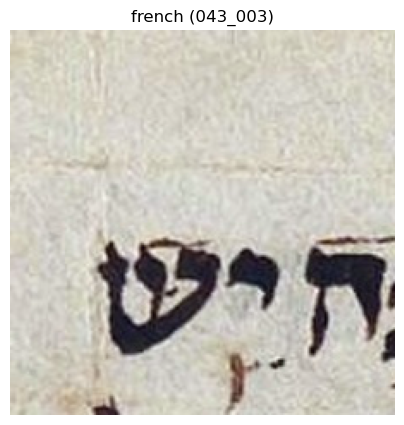

In [34]:
splits =  GrandparentSplitter (train_name='train', valid_name='val')(patches)
tfm = SingleComponentTransform(patches, label_func, splits)
tfm(patches[0]).show()

<Axes: title={'center': 'french (001_003)'}>

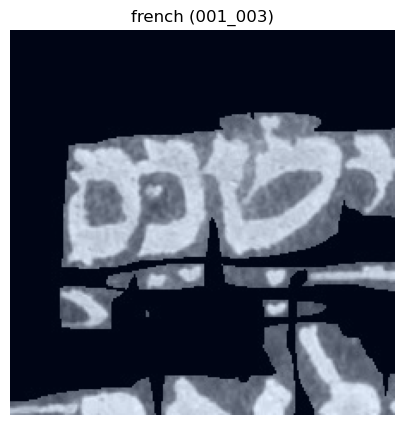

In [35]:
tls = TfmdLists(patches, tfm, splits=splits)
show_at(tls.valid, 0)

In [36]:
dls = tls.dataloaders(
    bs=32,
    # after_batch=[*aug_transforms()],
    after_batch=[Brightness(), Contrast()]
)

In [37]:

@typedispatch
def show_batch(
    x: SingleImage,
    y,
    samples,
    ctxs=None,
    max_n=6,
    nrows=None,
    ncols=2,
    figsize=None,
    **kwargs
):
    # x is a batched SingleImage:
    #   x[0]: imgs_batch  (bs, C, H, W) or (bs, H, W, C)
    #   x[1]: either labels_batch or (labels_batch, pids_batch)
    if figsize is None:
        figsize = (ncols * 6, math.ceil(max_n / ncols) * 3)

    imgs_batch = x[0]
    bs = imgs_batch.shape[0]
    n = min(bs, max_n)

    meta = x[1] if len(x) > 1 else None
    labels_batch, pids_batch = None, None

    if isinstance(meta, (tuple, fastuple)):
        if len(meta) == 2:
            labels_batch, pids_batch = meta
        elif len(meta) == 0:
            labels_batch = pids_batch = None
        else:
            labels_batch, pids_batch = meta, None
    elif meta is not None:
        labels_batch, pids_batch = meta, None

    if ctxs is None:
        ctxs = get_grid(n, nrows=nrows, ncols=ncols, figsize=figsize)

    for i, ctx in enumerate(ctxs[:n]):
        img_i = imgs_batch[i]

        label_i = labels_batch[i] if labels_batch is not None else None
        pid_i   = pids_batch[i]   if pids_batch   is not None else None

        if label_i is not None and pid_i is not None:
            item = SingleImage(img_i, (label_i, pid_i))
        elif label_i is not None:
            item = SingleImage(img_i, label_i)
        else:
            item = SingleImage(img_i,)

        item.show(ctx=ctx, **kwargs)

    return ctxs


Train

In [38]:

class BinaryHierarchicalLoss(nn.Module):
    def __init__(self, alpha=1.0, beta=0.5):
        """
        alpha: weight for per-component classification loss
        beta : weight for page-level consistency loss
        """
        super().__init__()
        self.ce = nn.CrossEntropyLoss()
        self.alpha = alpha
        self.beta = beta

    def forward(self, out, targ):
        """
        out  : [N, 2] logits (french/german)
        targ : tuple (labels, pids)
            - labels: tensor [N] with 0/1 (french/german)
            - pids  : list of page IDs (len N, strings)
        """
        if len(targ) == 0:
            return torch.tensor(0.0, device=out.device)
        labels, pids = targ

        # ---- component-level CE ----
        comp_loss = self.ce(out, labels.long())

        # ---- page-level CE ----
        page_logits = {}
        page_targets = {}

        for logit, t, pid in zip(out, labels, pids):
            if pid not in page_logits:
                page_logits[pid] = []
                page_targets[pid] = t
            page_logits[pid].append(logit)

        agg_logits = torch.stack([torch.stack(v).mean(0) for v in page_logits.values()])
        agg_targets = torch.stack(list(page_targets.values()))

        page_loss = self.ce(agg_logits, agg_targets.long())

        return self.alpha * comp_loss + self.beta * page_loss


In [39]:
def classifier_splitter(m):
    "Param-groups: ➀ encoder (frozen first), ➁ head (trainable first)."
    return [params(m.encoder), params(m.head)]


In [40]:
class PageIdRoutingCB(Callback):
    "Ensure model/loss sees (same, pid1, pid2) but metrics see only (same,)."
    def before_batch(self):
        # unpack batch target
        yb = self.yb
        if len(yb) == 1 and isinstance(yb[0], (tuple, list)):
            if len(yb[0]) > 1:
                script, pid = yb[0]
            else:
                return
        elif len(yb) == 2:
            script, pid = yb[:2]
        else:
            return  # nothing special

        # convert `same` to LongTensor on the right device
        script_t = torch.as_tensor(script, dtype=torch.long, device=self.dls.device)

        # stash full + simple versions
        self._full_yb = ((script_t, pid),)
        self._simple_yb = (script_t,)

        # by default, expose full tuple to loss
        self.learn.yb = self._full_yb

    def after_batch(self):
        # right after computing loss, swap back to simple yb
        # so metrics / recorder don’t choke
        if hasattr(self, "_simple_yb"):
            self.learn.yb = self._simple_yb

In [33]:
learn = Learner(
    dls,
    model,
    loss_func = BinaryHierarchicalLoss(alpha=1., beta=0.5),
    splitter  = classifier_splitter,   # NOT twin_splitter any more
    metrics   = accuracy
).add_cb(PageIdRoutingCB())

learn.freeze()                   # freezes encoder group
learn.fit_one_cycle(1, 1e-6)

learn.export(MODELS_DIR / "learner_binary_class.pkl")


epoch,train_loss,valid_loss,accuracy,time
0,0.023883,0.022349,0.992701,09:15


## Inference

Load the Inference Learner

In [34]:

learn_inf = load_learner(MODELS_DIR / "learner_binary_class.pkl")
learn_inf.metrics = []


Evaluate a Page Whether it's French or German

In [35]:

def evaluate_page(page_path: Path) -> dict[str, int]:
    # 1. Collect patches from the page
    patches = extract_patches(page_path)
    if not patches:   # no CCs found
        return {"french": 0, "german": 0}

    # 2. Build inference dataloader (no labels)
    dl = learn_inf.dls.test_dl(
        patches, bs=32, shuffle=False, with_labels=False
    )

    # 3. Run predictions (skip loss computation)
    preds, _ = learn_inf.get_preds(dl=dl, with_loss=False, reorder=False)
    if preds is None or len(preds) == 0:
        return {"french": 0, "german": 0}

    # 4. Aggregate counts
    index_to_label = {0: "french", 1: "german"}
    label_to_count = {"french": 0, "german": 0}
    for idx in preds.argmax(dim=1).tolist():
        label_to_count[index_to_label[idx]] += 1

    return label_to_count


Check our Performance on the Validation Dataset

In [36]:
page_paths = get_image_files(DS_ROOT / "val/french") + get_image_files(DS_ROOT / "val/german")
manuscripts = {}
for page_path in page_paths:
    ms_id = page_path.stem.split("_")[0]
    counts = evaluate_page(page_path)
    total  = sum(counts.values())

    # Handle edge case: no patches detected
    if total == 0:
        print(f"  {page_path.name:<40}  —  no patches detected")
        continue

    stats = manuscripts.setdefault(ms_id, {"french": 0, "german": 0, "components": 0})
    stats["french"]     += counts["french"]
    stats["german"]     += counts["german"]
    stats["components"] += total


In [37]:
rows = []
for ms_id, s in manuscripts.items():
    total = s["components"]
    rows.append({
        "MS ID":     ms_id,
        "p(French)": s["french"]  / total,
        "p(German)": s["german"]  / total,
        "Components": total
    })

(df := pd.DataFrame(rows)                       # build the frame
        .sort_values("MS ID")                   # sort by MS
        .reset_index(drop=True)                 # tidy index
).to_csv(RESULTS_DIR / "validation_results.csv",
         index=False,                           # no extra column
         float_format="%.2f")

Runm the Inference on the Test Dataset

In [38]:
page_paths = get_image_files(DS_ROOT / "test/french") + get_image_files(DS_ROOT / "test/german")
manuscripts = {}
for page_path in page_paths:
    ms_id = page_path.stem.split("_")[0]
    counts = evaluate_page(page_path)
    total  = sum(counts.values())

    # Handle edge case: no connected components detected
    if total == 0:
        print(f"  {page_path.name:<40}  —  no components detected")
        continue

    stats = manuscripts.setdefault(ms_id, {"french": 0, "german": 0, "components": 0})
    stats["french"]     += counts["french"]
    stats["german"]     += counts["german"]
    stats["components"] += total


In [39]:
rows = []
for ms_id, s in manuscripts.items():
    total = s["components"]
    rows.append({
        "MS ID":     ms_id,
        "p(French)": s["french"]  / total,
        "p(German)": s["german"]  / total,
        "Components": total
    })

(df := pd.DataFrame(rows)                       # build the frame
        .sort_values("MS ID")                   # sort by MS
        .reset_index(drop=True)                 # tidy index
).to_csv(RESULTS_DIR / "test_results.csv",
         index=False,                           # no extra column
         float_format="%.2f")

## Visualize with Grad Cam

In [43]:

from matplotlib import text


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -----------------------------------------------------------------------------
# 1. Load binary classifier (Stage 2 only)
# -----------------------------------------------------------------------------
learner_binary_class = load_learner(MODELS_DIR / "learner_binary_class.pkl")
model_bin = learner_binary_class.model.to(device)
model_bin.eval()

# We assume model_bin.encoder is your resnet50 body: Sequential[0..7], encoder[7] = layer4
TARGET_LAYER = model_bin.encoder[7][-1]  # last bottleneck of layer4


# -----------------------------------------------------------------------------
# 2. Hooks for Grad-CAM
# -----------------------------------------------------------------------------
class HookCAM:
    def __init__(self, module):
        self.stored = []
        self.hook = module.register_forward_hook(self.hook_func)

    def hook_func(self, module, inputs, outputs):
        self.stored.append(outputs.detach().clone())

    def __enter__(self, *args):
        return self

    def __exit__(self, *args):
        self.hook.remove()


class HookCAMBwd:
    def __init__(self, module):
        self.stored = []
        self.hook = module.register_full_backward_hook(self.hook_func)

    def hook_func(self, module, grad_inputs, grad_outputs):
        # grad_outputs[0]: d(score)/d(feature_map)
        self.stored.append(grad_outputs[0].detach().clone())

    def __enter__(self, *args):
        return self

    def __exit__(self, *args):
        self.hook.remove()


# -----------------------------------------------------------------------------
# 3. Grad-CAM core helper
# -----------------------------------------------------------------------------
def gradcam_from_acts_grads(acts: torch.Tensor, grads: torch.Tensor) -> torch.Tensor:
    """
    acts:  [B, C, H, W] feature maps
    grads: [B, C, H, W] gradients d(score)/d(acts)
    returns: [B, 1, H, W] Grad-CAM maps normalized to [0, 1] per sample
    """
    # Channel-wise weights by global-average pooling the gradients
    weights = grads.mean(dim=(2, 3), keepdim=True)  # [B, C, 1, 1]

    # Weighted sum over channels
    cam = (weights * acts).sum(dim=1, keepdim=True)  # [B, 1, H, W]

    # ReLU + per-sample normalization
    cam = torch.relu(cam)
    B = cam.shape[0]
    cam_flat = cam.view(B, -1)
    cam_min = cam_flat.min(dim=1, keepdim=True)[0].view(B, 1, 1, 1)
    cam_max = cam_flat.max(dim=1, keepdim=True)[0].view(B, 1, 1, 1)
    cam_norm = (cam - cam_min) / (cam_max - cam_min + 1e-8)
    return cam_norm  # [B,1,H,W]


def gradcam_for_patch(img_ts: torch.Tensor) -> np.ndarray:
    """
    Compute Grad-CAM for a single patch using the binary classifier.
    img_ts: [1, 3, H, W] tensor after image_tfm
    returns: H×W numpy array in [0,1]
    """
    model_bin.eval()

    with HookCAM(TARGET_LAYER) as f_hook, HookCAMBwd(TARGET_LAYER) as b_hook:
        f_hook.stored.clear()
        b_hook.stored.clear()

        logits = model_bin(img_ts.to(device))  # [1, num_classes]
        B, C = logits.shape

        # Target class = predicted class (per patch)
        target_idx = logits.argmax(dim=1)  # [1]
        scores = logits[torch.arange(B, device=device), target_idx].sum()

        model_bin.zero_grad(set_to_none=True)
        scores.backward()

        acts  = f_hook.stored[-1]   # [1, C, H', W']
        grads = b_hook.stored[-1]   # [1, C, H', W']

    cams = gradcam_from_acts_grads(acts, grads)  # [1,1,H',W']
    H, W = img_ts.shape[-2:]
    cam_up = F.interpolate(cams, size=(H, W), mode="bilinear", align_corners=False)  # [1,1,H,W]
    cam_np = cam_up[0, 0].detach().cpu().numpy()  # H×W in [0,1]
    return cam_np


# -----------------------------------------------------------------------------
# 4. Page-level helpers
# -----------------------------------------------------------------------------
def find_page_image(ms_id: str, page_id: str, region_id: str) -> Path:
    stem = f"{ms_id}_{page_id}_{region_id}"
    exts = [".jpg", ".jpeg", ".png", ".tif", ".tiff"]
    matches = []
    for ext in exts:
        matches.extend(DS_ROOT.rglob(stem + ext))

    if not matches:
        raise FileNotFoundError(f"No page image found for {stem} under {DS_ROOT}")

    matches = sorted(matches)
    if len(matches) > 1:
        print(f"Warning: multiple matches for {stem}, using: {matches[0]}")
    return matches[0]



def generate_attention_overlay_page(
    image_rgb: np.ndarray,          # H×W×3 uint8 RGB
    heatmap_page: np.ndarray,       # H×W float32
    alpha: float = 0.35,
    colormap: int = cv2.COLORMAP_VIRIDIS,  # thesis-safe
    q_low: float = 0.02,            # robust normalization
    q_high: float = 0.98,
    gamma: float = 1.5,             # emphasize peaks; try 1.0–2.0
    thr: float = 0.25,              # suppress low activations; set None to disable
) -> np.ndarray:
    H, W, _ = image_rgb.shape
    hm = heatmap_page.astype(np.float32)

    if hm.shape != (H, W):
        hm = cv2.resize(hm, (W, H), interpolation=cv2.INTER_LINEAR)

    # Robust normalization using quantiles
    lo = float(np.quantile(hm, q_low))
    hi = float(np.quantile(hm, q_high))
    if hi > lo:
        hm = (hm - lo) / (hi - lo + 1e-8)
    else:
        hm = np.zeros_like(hm, dtype=np.float32)

    hm = np.clip(hm, 0.0, 1.0)

    # Gamma shaping
    if gamma != 1.0:
        hm = np.power(hm, gamma)

    # Threshold low activations (reduces noisy haze)
    if thr is not None:
        hm = np.where(hm >= thr, hm, 0.0)

    cam_uint8 = (255.0 * hm).astype(np.uint8)

    # OpenCV colormaps are applied in BGR space; convert at the end.
    heatmap_bgr = cv2.applyColorMap(cam_uint8, colormap)
    image_bgr = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)

    overlay_bgr = cv2.addWeighted(image_bgr, 1 - alpha, heatmap_bgr, alpha, 0)
    overlay_rgb = cv2.cvtColor(overlay_bgr, cv2.COLOR_BGR2RGB)
    return overlay_rgb
# -----------------------------------------------------------------------------
# 5. Main function: patchify, per-patch Grad-CAM, aggregate, overlay, save
# -----------------------------------------------------------------------------
def save_binary_gradcam_page(ms_id: str, page_id: str, region_id:str, patch_size: int = 224):
    """
    1. Find page image for (ms_id, page_id).
    2. Patchify it with `extract_patches`.
    3. Run binary classifier + Grad-CAM on each patch.
    4. Aggregate all patch CAMs into a page-sized heatmap.
    5. Overlay heatmap over original page and save to RESULTS_DIR.
    """
    # 1) Locate page image
    page_path = find_page_image(ms_id, page_id, region_id)
    print(f"Using page image: {page_path}")

    # 2) Read original page and get size
    page_bgr = cv2.imread(str(page_path))
    if page_bgr is None:
        raise FileNotFoundError(f"Could not read page image: {page_path}")

    page_rgb = cv2.cvtColor(page_bgr, cv2.COLOR_BGR2RGB)
    H, W, _ = page_rgb.shape

    # 3) Patchify using your existing function
    patches = extract_patches(page_path, patch_size=patch_size)
    print(f"Extracted {len(patches)} patches for page {ms_id}_{page_id}")

    # 4) Prepare global heatmap & counter
    heatmap_page = np.zeros((H, W), dtype=np.float32)
    count_page   = np.zeros((H, W), dtype=np.float32)

    # 5) Per-patch Grad-CAM
    for p in patches:
        # Get padded 224×224 RGB patch as PIL image
        patch_pil = p.pil()
        img_ts = image_tfm(patch_pil)[None, ...]  # [1,3,patch_size,patch_size]

        cam_patch = gradcam_for_patch(img_ts)     # [patch_size, patch_size] in [0,1]

        x, y, w, h = p.bbox
        x_end = min(x + w, W)
        y_end = min(y + h, H)
        pw = x_end - x
        ph = y_end - y
        if pw <= 0 or ph <= 0:
            continue  # patch fully outside image (shouldn't really happen)

        # Accumulate heat over the corresponding region on the page
        heatmap_page[y:y_end, x:x_end] += cam_patch[:ph, :pw]
        count_page[y:y_end, x:x_end]   += 1.0

    # 6) Average over overlaps (if any; with stride=patch_size it's just edges)
    mask = count_page > 0
    heatmap_page[mask] /= count_page[mask]

    # 6.5) Light smoothing to reduce patch seams (minimal but very effective)
    # Kernel size should be odd. 11 or 15 works well for 224 patches.
    heatmap_page = cv2.GaussianBlur(heatmap_page, (11, 11), sigmaX=0) 

    # 7) Overlay and save
    overlay_rgb = generate_attention_overlay_page(page_rgb, heatmap_page, alpha=0.35)

    out_dir = RESULTS_DIR / f"{ms_id}_{page_id}_overlays"
    out_dir.mkdir(parents=True, exist_ok=True)
    out_path = out_dir / f"{ms_id}_{page_id}_{region_id}_overlay.jpg"
    overlay_bgr = cv2.cvtColor(overlay_rgb, cv2.COLOR_RGB2BGR)
    cv2.imwrite(str(out_path), overlay_bgr)


# -----------------------------------------------------------------------------
# Example call
# -----------------------------------------------------------------------------
save_binary_gradcam_page("021", "000", "00", patch_size=224)


Using page image: ASC_dataset_v3_augmented/test/german/021_000_00.jpg
Extracted 77 patches for page 021_000
